# 08 · Gateway Modbus → MQTT com report by exception

**Objetivo:** juntar os notebooks 01 e 05. Um gateway de borda lê um equipamento Modbus e publica no MQTT, mas **só quando vale a pena**:

* **Tabela de tags**: endereço, tipo, escala, unidade e deadband por variável
* **Report by exception**: publica só se o valor mudou mais que o deadband
* **Heartbeat**: republica de tempos em tempos, mesmo parado, para distinguir "estável" de "morto"
* **Qualidade**: se o equipamento parar de responder, avisa

In [1]:
# Configuração: deixa a raiz do repositório no caminho de import
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from common.notebook import load, run_in_background, require_broker
require_broker()
import os, time
plant = load("01-modbus-tcp-basics/plant_server.py")
run_in_background(lambda: plant.main(port=5020), port=5020)
os.environ["MODBUS_PORT"] = "5020"
gw = load("08-modbus-to-mqtt-gateway/gateway.py")

broker MQTT encontrado em localhost:1883


servidor ativo na porta 5020


## 1. A tabela de tags

In [2]:
import pandas as pd
pd.DataFrame([{"tag": t.name, "function code": t.fc, "endereço": t.address, "escala": t.scale,
               "unidade": t.unit, "deadband": t.deadband, "heartbeat (s)": t.heartbeat_s} for t in gw.TAGS])

,tag,function code,endereço,escala,unidade,deadband,heartbeat (s)
0,level,4,0,0.1,%,1.0,30.0
1,temperature,4,1,0.1,degC,0.2,30.0
2,level_sp,3,0,0.1,%,0.0,30.0
3,outflow,3,1,1.0,%,0.0,30.0
4,pump_cmd,1,0,1.0,,0.0,30.0
5,high_level,2,0,1.0,,0.0,30.0
6,pump_running,2,1,1.0,,0.0,30.0


Essa tabela é o coração de qualquer gateway comercial (Kepware, HighByte, Node-RED com nós Modbus). O deadband de **1 %** no nível e **0,2 °C** na temperatura diz: "mudanças menores que isso são ruído".

## 2. Ligando a bomba para o processo se mexer

In [3]:
from pymodbus.client import ModbusTcpClient
with ModbusTcpClient("localhost", port=5020) as c:
    c.write_coil(0, True, slave=1)
print("bomba ligada, o nível vai subir cerca de 1,2 % por segundo")

bomba ligada, o nível vai subir cerca de 1,2 % por segundo


## 3. Rodando o gateway por 20 segundos (leitura a cada 0,5 s)

In [4]:
# Um observador conta o que chega de fato ao broker
from common.mqtt import client as mqtt_client, HOST, PORT
chegou = []
obs = mqtt_client()
obs.on_message = lambda c, u, m: None if m.retain else chegou.append((time.time(), m.topic.split("/")[-1], m.payload.decode()))  # ignora o que ficou retido de execuções anteriores
obs.connect(HOST, PORT); obs.subscribe(gw.ROOT + "/#"); obs.loop_start()

stats = gw.run(seconds=20, poll_s=0.5, verbose=False)
time.sleep(0.5); obs.loop_stop(); obs.disconnect()
print(f"leituras Modbus : {stats['reads']}")
print(f"publicações MQTT: {stats['sent']}")
print(f"economia        : {100 * (1 - stats['sent'] / stats['reads']):.0f} %")

leituras Modbus : 280
publicações MQTT: 28
economia        : 90 %


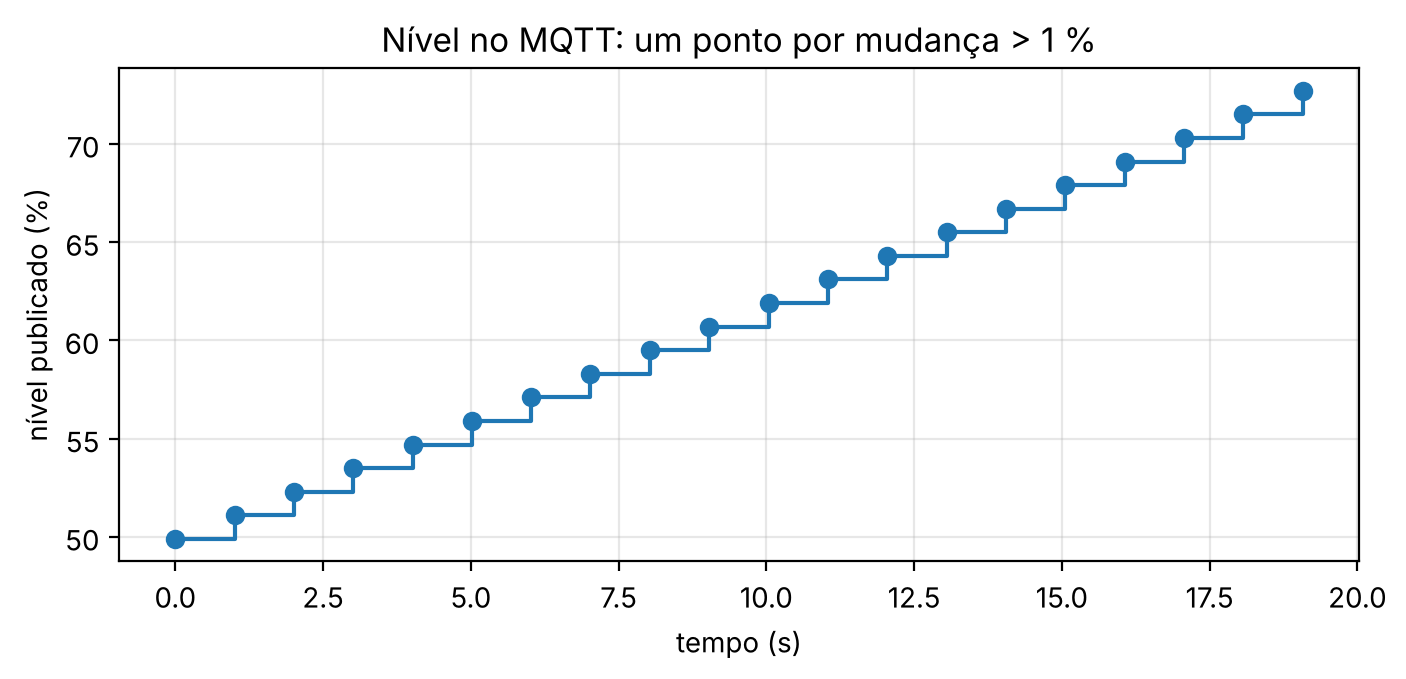

mensagens por tag: {'level': 20, 'status': 2, 'temperature': 2, 'pump_running': 2, 'device': 1, 'level_sp': 1, 'outflow': 1, 'pump_cmd': 1, 'high_level': 1}


In [5]:
import json, matplotlib.pyplot as plt
nivel = [(t, json.loads(p)["value"]) for t, tag, p in chegou if tag == "level" and p.startswith("{")]
t0 = nivel[0][0]
plt.figure(figsize=(8, 3.2))
plt.step([t - t0 for t, _ in nivel], [v for _, v in nivel], where="post", marker="o")
plt.xlabel("tempo (s)"); plt.ylabel("nível publicado (%)"); plt.title("Nível no MQTT: um ponto por mudança > 1 %")
plt.grid(alpha=.3); plt.show()
print("mensagens por tag:", pd.Series([tag for _, tag, _ in chegou]).value_counts().to_dict())

**Interpretação**

* O gateway leu as 7 tags **40 vezes** (280 leituras), mas publicou só uma fração. Cada degrau do gráfico é uma publicação: o nível só é enviado quando anda mais de 1 %.
* Tags que não mudaram (setpoint, válvula, nível alto) aparecem **uma vez**, no início. Elas voltariam a ser publicadas pelo heartbeat a cada 30 s.
* `pump_cmd` e `pump_running` mudam uma vez, quando a bomba liga.
* `_gateway/status` e `_gateway/device` são as mensagens de saúde do próprio gateway.

## 4. Qualidade: o que acontece quando o equipamento some

Vamos apontar o gateway para uma porta onde não há ninguém.

In [6]:
import logging; logging.getLogger("pymodbus").setLevel(logging.CRITICAL)   # silencia o log de reconexão
os.environ["MODBUS_PORT"] = "5999"
gw_sem_device = load("08-modbus-to-mqtt-gateway/gateway.py")
gw_sem_device.run(seconds=3, poll_s=0.5, verbose=True)

device quality -> BAD



42 tag reads, 0 MQTT publishes (100 % less upstream traffic)


{'reads': 42, 'sent': 0}

O gateway publicou `_gateway/device = bad: no response`, retido. Um consumidor sabe que **os últimos valores não são confiáveis**, em vez de continuar mostrando o último nível como se fosse atual. Isso é o que no OPC UA se chama *StatusCode* e no Sparkplug, *quality*.

## Resumo

* **Poll rápido, publique pouco**: a rede da planta aguenta polling; o broker, o historiador e a nuvem preferem só mudanças.
* Deadband por tag, **heartbeat** para valores estáveis e **qualidade** para falhas de comunicação são o mínimo de um gateway sério.
* Cuidado ao escolher o deadband: grande demais esconde eventos reais, pequeno demais vira ruído.